# Mini-Hackatón · Modelo de Machine Learning para predicción de diabetes

**Autor:** Equipo PITUFOS: JUAN ANTONIO RAMIREZ ESCAMILLA, MANUEL DE JESUS RAMIRO VELAZQUEZ TAPIA, EDUARDO ABURTO ANGULO, JUAN SINUE MONTENEGRO VALLEJO. · Maester en Inteligencia Artificial, Universidad Tecmilenio
**Reto:** *Generar un modelo de inteligencia artificial de Machine Learning*
**Dataset:** Pima Indians Diabetes Database — 768 registros, 8 variables clínicas + variable objetivo (`Outcome`)

---

### Resumen ejecutivo

| Indicador | Resultado |
|---|---|
| **Modelo final** | Regresión logística regularizada (L2, C = 0.5), elegida entre 6 algoritmos |
| **ROC-AUC** | 0.845 en validación cruzada · 0.813 en prueba (IC 95 %: 0.741 – 0.874) |
| **Recall (sensibilidad)** | **0.889** (IC 95 %: 0.800 – 0.968) — detecta 48 de los 54 casos positivos |
| Precisión · F1 · Exactitud | 0.571 · 0.696 · 0.727 |
| **Valor predictivo negativo** | **0.914** — cuando el modelo descarta, acierta 9 de cada 10 veces |
| **Umbral de operación** | **0.35**, calibrado para recall ≥ 0.85 (no el 0.50 por defecto) |
| Variable dominante | Glucosa: ×3.19 de razón de momios por desviación estándar |

**La decisión de diseño que define este modelo:** se optimizó para **no dejar pasar casos positivos**, no para maximizar la exactitud. Mover el umbral de 0.50 a 0.35 baja los falsos negativos de 16 a 6 y sube los falsos positivos de 25 a 36. El intercambio es deliberado: un falso positivo cuesta una prueba confirmatoria; un falso negativo cuesta una paciente que se va sin seguimiento.

---

### Cómo está organizado este notebook

| # | Sección | Qué resuelve |
|---|---------|--------------|
| 1 | Configuración | Entorno, semilla, paleta de color |
| 2 | Carga de datos | Lectura reproducible del dataset |
| 3 | Diccionario de variables | Qué significa cada columna |
| 4 | Calidad de datos | Ceros biológicamente imposibles → faltantes |
| 5 | Análisis exploratorio | Balance de clases, distribuciones, correlaciones |
| 6 | Preparación | Partición estratificada y *pipelines* sin fuga de información |
| 7 | Modelado comparativo | Seis algoritmos con validación cruzada 5-fold |
| 8 | Optimización | Búsqueda de hiperparámetros del modelo ganador |
| 9 | Umbral de decisión | Calibración del punto de corte para tamizaje |
| 10 | Evaluación final | Precisión, recall, F1, matriz de confusión, ROC y PR en *test* |
| 11 | Interpretabilidad | Razones de momios e importancia por permutación |
| 12 | Limitaciones | Qué **no** puede afirmar este modelo |
| 13 | Conclusiones | Lectura ejecutiva y checklist de entregables |

> **Reproducibilidad:** el notebook corre de principio a fin en Google Colab sin credenciales ni archivos previos. `Entorno de ejecución → Ejecutar todas las celdas`.

## 1. Configuración del entorno

Semilla fija (`SEED = 42`) en partición, modelos y remuestreos: cualquier persona que ejecute el notebook obtiene exactamente los mismos números.

La paleta usa azul (#1464A5) y coral (#C94A3F), un par validado para visión con deficiencia de color (ΔE CVD 16.6 en protanopía, 28.6 en visión normal), de modo que las gráficas se leen igual impresas en gris o vistas por una persona daltónica.

In [1]:
# === 1. Configuración del entorno ===
# Librerías estándar: todas vienen preinstaladas en Google Colab.
import json, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn

warnings.filterwarnings("ignore")          # mantiene la salida limpia; no oculta errores, solo avisos
SEED = 42
np.random.seed(SEED)

# Carpetas de salida (figuras, modelo serializado, datos)
for carpeta in ["data", "models", "reports/figures"]:
    Path(carpeta).mkdir(parents=True, exist_ok=True)

# --- Paleta e identidad visual -------------------------------------------------
AZUL, CORAL, MORADO = "#1464A5", "#C94A3F", "#8E6BB5"   # categóricos validados para daltonismo
AZUL_OSCURO, GRIS_TINTA, GRIS_SUAVE = "#0B3B66", "#2B2B2B", "#DCDCDC"
PAL_CLASE  = {0: AZUL, 1: CORAL}
ETIQ_CLASE = {0: "Sin diabetes", 1: "Con diabetes"}

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.labelcolor": GRIS_TINTA, "text.color": GRIS_TINTA,
    "axes.edgecolor": GRIS_SUAVE, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": GRIS_TINTA, "ytick.color": GRIS_TINTA,
    "grid.color": GRIS_SUAVE, "grid.linewidth": 0.8, "axes.grid": False,
    "legend.frameon": False, "lines.linewidth": 2.0,
})

def guardar(fig, nombre):
    # Guarda cada figura en reports/figures para reutilizarla en el reporte o el README
    ruta = f"reports/figures/{nombre}.png"
    fig.savefig(ruta)
    return ruta

print(f"Python      {platform.python_version()}")
print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"scikit-learn{sklearn.__version__:>9}")
print(f"matplotlib  {mpl.__version__}")
print(f"\nSemilla global: {SEED}")

Python      3.13.17
pandas      3.0.5
numpy       2.5.3
scikit-learn    1.9.1
matplotlib  3.11.2

Semilla global: 42


## 2. Carga de datos

El dataset es el **Pima Indians Diabetes Database** (768 × 9). El notebook intenta primero leer `data/diabetes.csv` —si el organizador entrega el CSV, basta con colocarlo ahí— y si no existe lo descarga de un espejo público con el mismo contenido y el mismo esquema que la versión de Kaggle (`mragpavank/diabetes`). Así corre en Colab sin credenciales de Kaggle.

In [2]:
# === 2. Carga de datos ===
RUTA_LOCAL = Path("data/diabetes.csv")
URL_ESPEJO = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

if RUTA_LOCAL.exists():
    df = pd.read_csv(RUTA_LOCAL)
    origen = f"archivo local ({RUTA_LOCAL})"
else:
    df = pd.read_csv(URL_ESPEJO)
    df.to_csv(RUTA_LOCAL, index=False)      # se guarda para que la corrida sea reproducible offline
    origen = "espejo público (descarga directa)"

print(f"Origen de los datos : {origen}")
print(f"Dimensiones         : {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"Duplicados exactos  : {df.duplicated().sum()}")
df.head()

Origen de los datos : archivo local (data/diabetes.csv)
Dimensiones         : 768 filas × 9 columnas
Duplicados exactos  : 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Diccionario de variables

| Variable | Significado | Unidad |
|---|---|---|
| `Pregnancies` | Número de embarazos | conteo |
| `Glucose` | Glucosa plasmática a 2 h en prueba de tolerancia oral | mg/dL |
| `BloodPressure` | Presión arterial diastólica | mm Hg |
| `SkinThickness` | Espesor del pliegue cutáneo del tríceps | mm |
| `Insulin` | Insulina sérica a 2 h | µU/mL |
| `BMI` | Índice de masa corporal | kg/m² |
| `DiabetesPedigreeFunction` | Índice de carga familiar de diabetes | adimensional |
| `Age` | Edad | años |
| **`Outcome`** | **Variable objetivo: 1 = diagnóstico positivo de diabetes** | 0 / 1 |

Toda la población del estudio son **mujeres de ascendencia Pima, de 21 años o más** (National Institute of Diabetes and Digestive and Kidney Diseases). Ese detalle es decisivo para la sección de limitaciones.

In [3]:
# === 3. Perfil estadístico inicial ===
print("Tipos de dato y nulos declarados:")
df.info()

print("\nEstadística descriptiva:")
df.describe().T.round(2)

Tipos de dato y nulos declarados:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Estadística descriptiva:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 4. Calidad de datos: los ceros que no son ceros

Un valor de `0` en glucosa, presión arterial, pliegue cutáneo, insulina o IMC es **biológicamente imposible**: codifica un dato faltante, no una medición. Tratarlo como cero real arrastra las medias hacia abajo y degrada cualquier modelo.

La decisión aquí es convertir esos ceros en `NaN` y **imputarlos con la mediana dentro del pipeline**, es decir, calculando la mediana solo con los datos de entrenamiento en cada partición de la validación cruzada. Imputar antes de partir sería fuga de información (*data leakage*) y pintaría métricas optimistas.

`Pregnancies` se deja intacta: cero embarazos es un valor legítimo.

Registros recodificados como faltantes:

               Ceros imposibles  % del total
Insulin                     374         48.7
SkinThickness               227         29.6
BloodPressure                35          4.6
BMI                          11          1.4
Glucose                       5          0.7


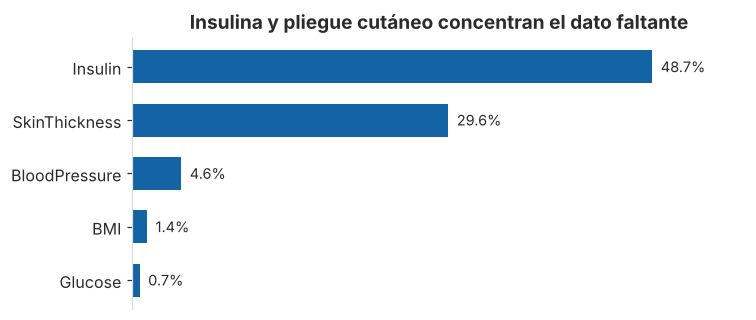

In [4]:
# === 4. Ceros imposibles → valores faltantes ===
COLS_CERO_IMPOSIBLE = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

ceros_antes = (df[COLS_CERO_IMPOSIBLE] == 0).sum()
df[COLS_CERO_IMPOSIBLE] = df[COLS_CERO_IMPOSIBLE].replace(0, np.nan)

faltantes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

resumen_calidad = pd.DataFrame({
    "Ceros imposibles": ceros_antes,
    "% del total": (ceros_antes / len(df) * 100).round(1),
}).sort_values("Ceros imposibles", ascending=False)
print("Registros recodificados como faltantes:\n")
print(resumen_calidad.to_string())

# --- Figura: magnitud del faltante por variable (una sola tonalidad = magnitud) ---
fig, ax = plt.subplots(figsize=(7.2, 3.2))
orden = faltantes.sort_values()
barras = ax.barh(orden.index, orden.values, color=AZUL, height=0.62)
for b, v in zip(barras, orden.values):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9.5, color=GRIS_TINTA)
ax.set_xlim(0, max(orden.values) * 1.18)
ax.set_xlabel("Porcentaje de registros sin medición")
ax.set_title("Insulina y pliegue cutáneo concentran el dato faltante")
ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
guardar(fig, "01_faltantes"); plt.show()

## 5. Análisis exploratorio

Tres preguntas: **¿qué tan desbalanceadas están las clases?**, **¿qué variables separan a los dos grupos?** y **¿hay redundancia entre predictores?**

Sin diabetes (0): 500 casos  (65.1%)
Con diabetes (1): 268 casos  (34.9%)

Razón de desbalance: 1.87 : 1


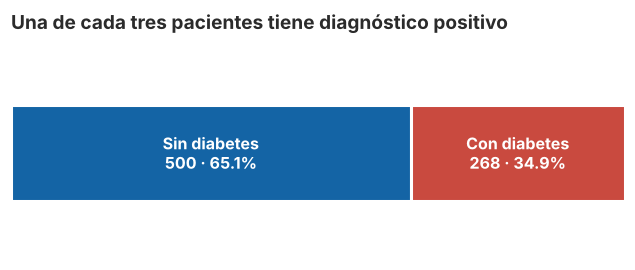

In [5]:
# === 5.1 Balance de clases ===
conteo = df["Outcome"].value_counts().sort_index()
prevalencia = df["Outcome"].mean()
print(f"Sin diabetes (0): {conteo[0]} casos  ({(1-prevalencia)*100:.1f}%)")
print(f"Con diabetes (1): {conteo[1]} casos  ({prevalencia*100:.1f}%)")
print(f"\nRazón de desbalance: {conteo[0]/conteo[1]:.2f} : 1")

fig, ax = plt.subplots(figsize=(7.2, 2.5))
izq = 0
for clase in [0, 1]:
    ancho = conteo[clase] / conteo.sum() * 100
    ax.barh(0, ancho, left=izq, color=PAL_CLASE[clase], height=0.45,
            edgecolor="white", linewidth=2)
    ax.text(izq + ancho / 2, 0, f"{ETIQ_CLASE[clase]}\n{conteo[clase]} · {ancho:.1f}%",
            ha="center", va="center", color="white", fontsize=10.5, fontweight="bold")
    izq += ancho
ax.set_xlim(0, 100); ax.set_ylim(-0.5, 0.5); ax.axis("off")
ax.set_title("Una de cada tres pacientes tiene diagnóstico positivo", pad=12, loc="left")
guardar(fig, "02_balance_clases"); plt.show()

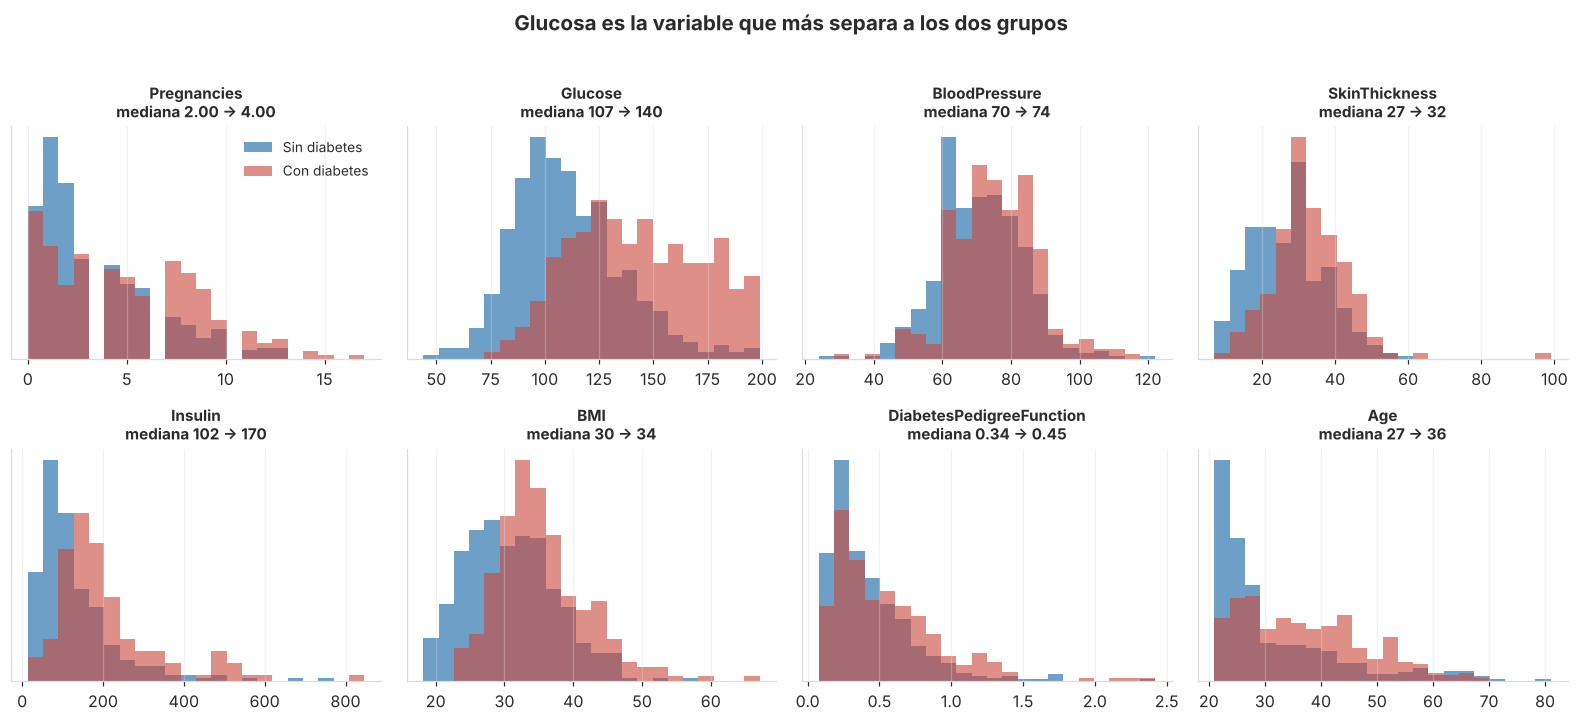

In [6]:
# === 5.2 Distribución de cada variable por clase ===
# Pequeños múltiplos: misma escala visual, lectura rápida de qué variable separa grupos.
VARIABLES = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.4))

for ax, var in zip(axes.ravel(), VARIABLES):
    datos = [df.loc[df["Outcome"] == c, var].dropna() for c in [0, 1]]
    rango = (min(d.min() for d in datos), max(d.max() for d in datos))
    for clase, serie in zip([0, 1], datos):
        ax.hist(serie, bins=22, range=rango, density=True, alpha=0.62,
                color=PAL_CLASE[clase], label=ETIQ_CLASE[clase])
    # Diferencia de medianas: cuantifica la separación que se ve en la gráfica
    d0, d1 = datos[0].median(), datos[1].median()
    fmt = ".2f" if max(abs(d0), abs(d1)) < 10 else ".0f"   # escala adaptativa: evita "0 → 0"
    ax.set_title(f"{var}\nmediana {d0:{fmt}} → {d1:{fmt}}", fontsize=10, fontweight="bold")
    ax.set_yticks([]); ax.grid(axis="x", alpha=0.35)

axes.ravel()[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Glucosa es la variable que más separa a los dos grupos", fontsize=13.5,
             fontweight="bold", y=1.02, x=0.5)
fig.tight_layout()
guardar(fig, "03_distribuciones"); plt.show()

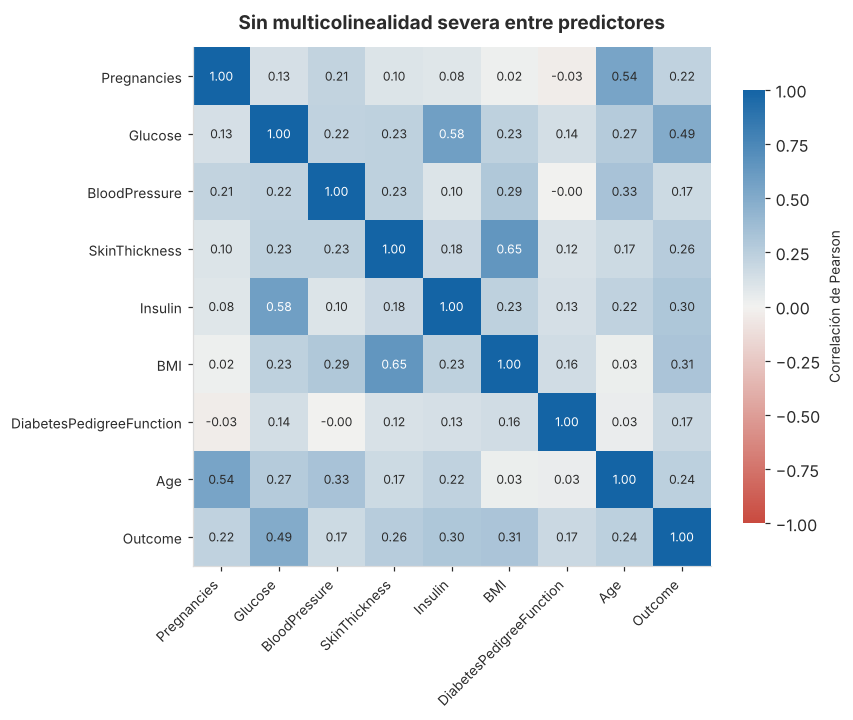

Correlación de cada variable con Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


In [7]:
# === 5.3 Correlaciones (escala divergente: dos polos + gris neutro) ===
corr = df.corr(numeric_only=True)

from matplotlib.colors import LinearSegmentedColormap
cmap_div = LinearSegmentedColormap.from_list("coral_azul", [CORAL, "#F2F2F0", AZUL])

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(corr.values, cmap=cmap_div, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.55 else GRIS_TINTA)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
cb.set_label("Correlación de Pearson", fontsize=9)
ax.set_title("Sin multicolinealidad severa entre predictores", pad=12)
guardar(fig, "04_correlaciones"); plt.show()

print("Correlación de cada variable con Outcome:")
print(corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3).to_string())

## 6. Preparación: partición estratificada y *pipelines*

Dos reglas que sostienen la validez de todo lo que sigue:

1. **Partición estratificada 80/20** — el conjunto de prueba conserva la misma prevalencia (35 %) que el total, y no se toca hasta la sección 10.
2. **Imputación y escalamiento dentro del `Pipeline`** — así la mediana y la media/desviación se aprenden únicamente del subconjunto de entrenamiento de cada partición, sin fuga de información.

`class_weight="balanced"` compensa el desbalance 1.87 : 1 penalizando más los errores sobre la clase minoritaria, que es justo la clase clínicamente relevante.

In [8]:
# === 6. Partición y pipelines ===
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Entrenamiento : {X_train.shape[0]} registros · prevalencia {y_train.mean():.3f}")
print(f"Prueba        : {X_test.shape[0]} registros · prevalencia {y_test.mean():.3f}")

def construir_pipeline(modelo, escalar=True):
    # Imputación (mediana) + escalamiento opcional + clasificador, todo dentro de un solo objeto
    pasos = [("imputador", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalador", StandardScaler()))
    pasos.append(("clasificador", modelo))
    return Pipeline(pasos)

MODELOS = {
    "Regresión Logística": construir_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    "SVM (RBF)": construir_pipeline(
        SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
    "KNN (k=15)": construir_pipeline(
        KNeighborsClassifier(n_neighbors=15)),
    "Árbol de Decisión": construir_pipeline(
        DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED), escalar=False),
    "Random Forest": construir_pipeline(
        RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                               random_state=SEED, n_jobs=-1), escalar=False),
    "Gradient Boosting": construir_pipeline(
        GradientBoostingClassifier(random_state=SEED), escalar=False),
}
print(f"\n{len(MODELOS)} algoritmos a comparar: {', '.join(MODELOS)}")

Entrenamiento : 614 registros · prevalencia 0.349
Prueba        : 154 registros · prevalencia 0.351

6 algoritmos a comparar: Regresión Logística, SVM (RBF), KNN (k=15), Árbol de Decisión, Random Forest, Gradient Boosting


## 7. Modelado comparativo con validación cruzada

Seis algoritmos, **validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento únicamente**. La selección se decide aquí; el conjunto de prueba queda reservado como estimación honesta del desempeño final.

Métrica de selección: **ROC-AUC**, porque mide la capacidad de ordenar riesgo sin depender del umbral —el umbral se calibra aparte, en la sección 9—. Se reportan también F1, recall y precisión para ver el perfil completo de cada modelo.

In [9]:
# === 7. Comparación por validación cruzada (5-fold estratificado) ===
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = ["roc_auc", "average_precision", "f1", "recall", "precision", "accuracy"]

filas = []
for nombre, pipe in MODELOS.items():
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS, n_jobs=-1)
    filas.append({
        "Modelo": nombre,
        "ROC-AUC": cvres["test_roc_auc"].mean(),
        "± sd": cvres["test_roc_auc"].std(),
        "PR-AUC": cvres["test_average_precision"].mean(),
        "F1": cvres["test_f1"].mean(),
        "Recall": cvres["test_recall"].mean(),
        "Precisión": cvres["test_precision"].mean(),
        "Exactitud": cvres["test_accuracy"].mean(),
    })

tabla_cv = pd.DataFrame(filas).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
MODELO_GANADOR = tabla_cv.loc[0, "Modelo"]

print("Validación cruzada 5-fold sobre entrenamiento (614 registros):\n")
print(tabla_cv.round(3).to_string(index=False))
print(f"\n→ Modelo seleccionado por ROC-AUC: {MODELO_GANADOR}")
tabla_cv.round(4).to_csv("reports/metricas_validacion_cruzada.csv", index=False)

Validación cruzada 5-fold sobre entrenamiento (614 registros):

             Modelo  ROC-AUC  ± sd  PR-AUC    F1  Recall  Precisión  Exactitud
Regresión Logística    0.844 0.016   0.748 0.672   0.701      0.649      0.762
          SVM (RBF)    0.837 0.031   0.709 0.690   0.762      0.637      0.761
      Random Forest    0.832 0.024   0.721 0.687   0.729      0.651      0.769
         KNN (k=15)    0.832 0.030   0.716 0.632   0.571      0.719      0.769
  Gradient Boosting    0.819 0.016   0.713 0.631   0.598      0.672      0.756
  Árbol de Decisión    0.786 0.027   0.634 0.637   0.748      0.561      0.707

→ Modelo seleccionado por ROC-AUC: Regresión Logística


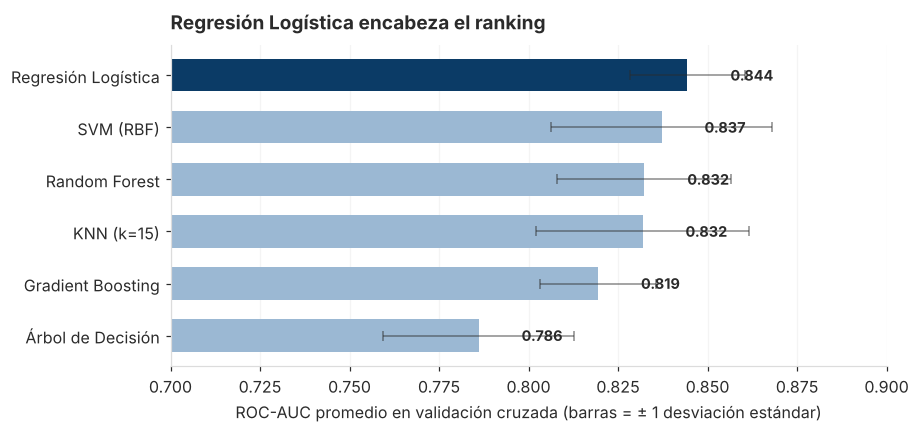

In [10]:
# === 7.1 Figura: ranking de modelos (una tonalidad = magnitud; ganador resaltado) ===
t = tabla_cv.sort_values("ROC-AUC")
colores = [AZUL_OSCURO if m == MODELO_GANADOR else "#9BB8D3" for m in t["Modelo"]]

fig, ax = plt.subplots(figsize=(8.4, 3.8))
barras = ax.barh(t["Modelo"], t["ROC-AUC"], color=colores, height=0.62,
                 xerr=t["± sd"], error_kw=dict(ecolor=GRIS_TINTA, elinewidth=1, capsize=3, alpha=0.55))
for b, v in zip(barras, t["ROC-AUC"]):
    ax.text(v + 0.012, b.get_y() + b.get_height() / 2, f"{v:.3f}",
            va="center", fontsize=9.5, color=GRIS_TINTA, fontweight="bold")
ax.set_xlim(0.70, 0.90)
ax.set_xlabel("ROC-AUC promedio en validación cruzada (barras = ± 1 desviación estándar)")
ax.set_title(f"{MODELO_GANADOR} encabeza el ranking", loc="left", pad=10)
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
guardar(fig, "05_ranking_modelos"); plt.show()

## 8. Optimización de hiperparámetros

Búsqueda exhaustiva (`GridSearchCV`) con la misma validación cruzada de 5 particiones, optimizando ROC-AUC. Se exploran los dos candidatos con mejor desempeño para confirmar que la elección no depende de una configuración por defecto afortunada.

In [11]:
# === 8. Búsqueda de hiperparámetros ===
REJILLAS = {
    "Regresión Logística": (
        construir_pipeline(LogisticRegression(max_iter=5000, class_weight="balanced",
                                              solver="liblinear", random_state=SEED)),
        {"clasificador__C": [0.01, 0.1, 0.5, 1, 3, 10],
         "clasificador__penalty": ["l1", "l2"]},
    ),
    "Random Forest": (
        construir_pipeline(RandomForestClassifier(class_weight="balanced", random_state=SEED,
                                                  n_jobs=-1), escalar=False),
        {"clasificador__n_estimators": [300, 600],
         "clasificador__max_depth": [4, 6, None],
         "clasificador__min_samples_leaf": [1, 3, 6]},
    ),
}

resultados_busqueda = {}
for nombre, (pipe, rejilla) in REJILLAS.items():
    busqueda = GridSearchCV(pipe, rejilla, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train)
    resultados_busqueda[nombre] = busqueda
    print(f"{nombre}")
    print(f"  mejor ROC-AUC (CV) : {busqueda.best_score_:.4f}")
    print(f"  mejores parámetros : {busqueda.best_params_}\n")

NOMBRE_FINAL = max(resultados_busqueda, key=lambda k: resultados_busqueda[k].best_score_)
modelo_final = resultados_busqueda[NOMBRE_FINAL].best_estimator_
auc_cv_final = resultados_busqueda[NOMBRE_FINAL].best_score_
print(f"→ Modelo final: {NOMBRE_FINAL}  (ROC-AUC en validación cruzada = {auc_cv_final:.4f})")

Regresión Logística
  mejor ROC-AUC (CV) : 0.8450
  mejores parámetros : {'clasificador__C': 0.5, 'clasificador__penalty': 'l2'}



Random Forest
  mejor ROC-AUC (CV) : 0.8417
  mejores parámetros : {'clasificador__max_depth': 4, 'clasificador__min_samples_leaf': 6, 'clasificador__n_estimators': 300}

→ Modelo final: Regresión Logística  (ROC-AUC en validación cruzada = 0.8450)


## 9. Calibración del umbral de decisión

El umbral por defecto de 0.5 **no es una ley**: es una convención que asume que un falso positivo y un falso negativo cuestan lo mismo. En tamizaje de diabetes no cuestan lo mismo. Un falso negativo es una paciente con diabetes que se va a casa sin seguimiento; un falso positivo es una prueba confirmatoria adicional, molesta pero barata y reversible.

El umbral se elige con **predicciones fuera de muestra sobre el entrenamiento** (`cross_val_predict`), nunca sobre el conjunto de prueba: así el punto de corte no se contamina con los datos usados para reportar el resultado final.

**Criterio:** el umbral más alto que mantiene **recall ≥ 0.85** —es decir, que detecta al menos 85 de cada 100 casos positivos— maximizando la precisión dentro de esa restricción.

Umbral de máxima F1 (referencia)      : 0.56
Umbral de tamizaje (recall ≥ 0.85) : 0.35

Comportamiento alrededor del umbral elegido (datos fuera de muestra):
 umbral  precision  recall    f1
   0.30      0.504   0.907 0.648
   0.31      0.518   0.897 0.656
   0.32      0.528   0.888 0.662
   0.33      0.535   0.883 0.667
   0.34      0.545   0.879 0.673
   0.35      0.551   0.864 0.673
   0.36      0.548   0.850 0.667
   0.37      0.552   0.836 0.665
   0.38      0.562   0.832 0.670
   0.39      0.571   0.832 0.677


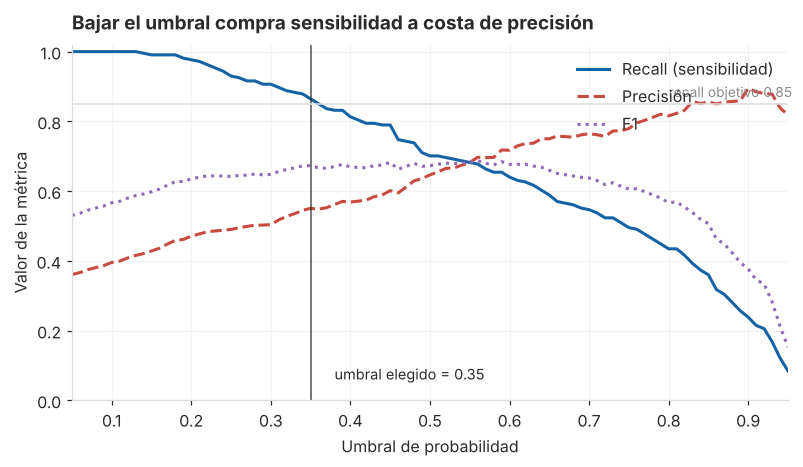

In [12]:
# === 9. Selección del umbral sobre predicciones fuera de muestra ===
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

RECALL_OBJETIVO = 0.85
rejilla_umbral = np.arange(0.05, 0.96, 0.01)
barrido = pd.DataFrame({
    "umbral": rejilla_umbral,
    "precision": [precision_score(y_train, (proba_oof >= t).astype(int), zero_division=0) for t in rejilla_umbral],
    "recall":    [recall_score(y_train, (proba_oof >= t).astype(int)) for t in rejilla_umbral],
    "f1":        [f1_score(y_train, (proba_oof >= t).astype(int), zero_division=0) for t in rejilla_umbral],
})

validos = barrido[barrido["recall"] >= RECALL_OBJETIVO]
UMBRAL = float(validos.loc[validos["precision"].idxmax(), "umbral"])
UMBRAL_F1 = float(barrido.loc[barrido["f1"].idxmax(), "umbral"])

print(f"Umbral de máxima F1 (referencia)      : {UMBRAL_F1:.2f}")
print(f"Umbral de tamizaje (recall ≥ {RECALL_OBJETIVO:.2f}) : {UMBRAL:.2f}")
print("\nComportamiento alrededor del umbral elegido (datos fuera de muestra):")
print(barrido[(barrido["umbral"] >= UMBRAL - 0.05) & (barrido["umbral"] <= UMBRAL + 0.05)].round(3).to_string(index=False))

# --- Figura: compromiso precisión / recall según el umbral ---
fig, ax = plt.subplots(figsize=(8.4, 4.2))
ax.plot(barrido["umbral"], barrido["recall"],    color=AZUL,   label="Recall (sensibilidad)")
ax.plot(barrido["umbral"], barrido["precision"], color=CORAL,  label="Precisión", linestyle="--")
ax.plot(barrido["umbral"], barrido["f1"],        color=MORADO, label="F1", linestyle=":")
ax.axvline(UMBRAL, color=GRIS_TINTA, linewidth=1.1, alpha=0.75)
ax.axhline(RECALL_OBJETIVO, color=GRIS_SUAVE, linewidth=1)
ax.annotate(f"umbral elegido = {UMBRAL:.2f}", xy=(UMBRAL, 0.06), xytext=(UMBRAL + 0.03, 0.06),
            fontsize=9.5, color=GRIS_TINTA)
ax.annotate(f"recall objetivo {RECALL_OBJETIVO:.2f}", xy=(0.80, RECALL_OBJETIVO + 0.02),
            fontsize=9, color="#8A8A8A")
ax.set_xlabel("Umbral de probabilidad"); ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.02); ax.set_xlim(0.05, 0.95)
ax.set_title("Bajar el umbral compra sensibilidad a costa de precisión", loc="left", pad=10)
ax.legend(loc="upper right"); ax.grid(alpha=0.3); ax.set_axisbelow(True)
guardar(fig, "06_umbral"); plt.show()

## 10. Evaluación final sobre el conjunto de prueba

Primera y única vez que se usan los 154 registros reservados. Se reportan las dos operaciones del mismo modelo: **umbral 0.5** (referencia) y **umbral de tamizaje calibrado** (operación propuesta).

In [13]:
# === 10.1 Métricas en prueba: umbral 0.5 vs. umbral calibrado ===
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_auc_score,
                             average_precision_score, roc_curve, classification_report)

modelo_final.fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)[:, 1]

def evaluar(y_real, proba, umbral, etiqueta):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "Operación": etiqueta, "Umbral": umbral,
        "Exactitud": accuracy_score(y_real, pred),
        "Precisión": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred),
        "F1": f1_score(y_real, pred, zero_division=0),
        "Especificidad": tn / (tn + fp),
        "VPN": tn / (tn + fn) if (tn + fn) else np.nan,
        "ROC-AUC": roc_auc_score(y_real, proba),
        "PR-AUC": average_precision_score(y_real, proba),
        "VP": tp, "FP": fp, "FN": fn, "VN": tn,
    }

tabla_test = pd.DataFrame([
    evaluar(y_test, proba_test, 0.50,   "Umbral por defecto"),
    evaluar(y_test, proba_test, UMBRAL, "Umbral de tamizaje"),
])
print(f"Modelo final: {NOMBRE_FINAL}   ·   Conjunto de prueba: {len(y_test)} registros\n")
print(tabla_test.round(3).to_string(index=False))

print("\n\nReporte de clasificación con el umbral de tamizaje:\n")
print(classification_report(y_test, (proba_test >= UMBRAL).astype(int),
                            target_names=["Sin diabetes", "Con diabetes"], digits=3))
tabla_test.round(4).to_csv("reports/metricas_prueba.csv", index=False)

Modelo final: Regresión Logística   ·   Conjunto de prueba: 154 registros

         Operación  Umbral  Exactitud  Precisión  Recall    F1  Especificidad   VPN  ROC-AUC  PR-AUC  VP  FP  FN  VN
Umbral por defecto    0.50      0.734      0.603   0.704 0.650           0.75 0.824    0.813   0.673  38  25  16  75
Umbral de tamizaje    0.35      0.727      0.571   0.889 0.696           0.64 0.914    0.813   0.673  48  36   6  64


Reporte de clasificación con el umbral de tamizaje:

              precision    recall  f1-score   support

Sin diabetes      0.914     0.640     0.753       100
Con diabetes      0.571     0.889     0.696        54

    accuracy                          0.727       154
   macro avg      0.743     0.764     0.724       154
weighted avg      0.794     0.727     0.733       154



In [14]:
# === 10.2 Intervalos de confianza por bootstrap (1 000 remuestreos) ===
# Con 154 registros de prueba, un número puntual sin intervalo exagera la precisión del resultado.
rng = np.random.default_rng(SEED)
indices = np.arange(len(y_test))
y_arr = y_test.to_numpy()

boot = {"ROC-AUC": [], "Recall": [], "Precisión": [], "F1": []}
for _ in range(1000):
    m = rng.choice(indices, size=len(indices), replace=True)
    if len(np.unique(y_arr[m])) < 2:          # remuestreo degenerado: se descarta
        continue
    pb, yb = proba_test[m], y_arr[m]
    pred = (pb >= UMBRAL).astype(int)
    boot["ROC-AUC"].append(roc_auc_score(yb, pb))
    boot["Recall"].append(recall_score(yb, pred))
    boot["Precisión"].append(precision_score(yb, pred, zero_division=0))
    boot["F1"].append(f1_score(yb, pred, zero_division=0))

ic = pd.DataFrame({
    "Métrica": list(boot),
    "Estimación": [np.mean(v) for v in boot.values()],
    "IC 95% inferior": [np.percentile(v, 2.5) for v in boot.values()],
    "IC 95% superior": [np.percentile(v, 97.5) for v in boot.values()],
})
print("Intervalos de confianza al 95 % (bootstrap, umbral de tamizaje):\n")
print(ic.round(3).to_string(index=False))

Intervalos de confianza al 95 % (bootstrap, umbral de tamizaje):

  Métrica  Estimación  IC 95% inferior  IC 95% superior
  ROC-AUC       0.812            0.741            0.874
   Recall       0.890            0.800            0.968
Precisión       0.571            0.467            0.674
       F1       0.694            0.602            0.776


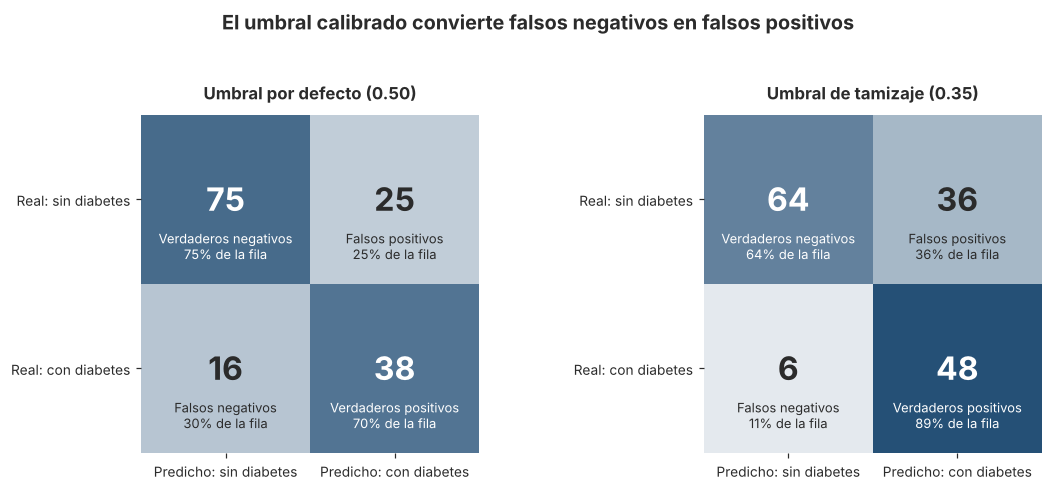

In [15]:
# === 10.3 Matrices de confusión: qué cambia al mover el umbral ===
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.3))
cmap_seq = LinearSegmentedColormap.from_list("azules", ["#FFFFFF", AZUL_OSCURO])

for ax, (umbral, titulo) in zip(axes, [(0.50, "Umbral por defecto (0.50)"),
                                       (UMBRAL, f"Umbral de tamizaje ({UMBRAL:.2f})")]):
    mc = confusion_matrix(y_test, (proba_test >= umbral).astype(int))
    mc_pct = mc / mc.sum(axis=1, keepdims=True)
    ax.imshow(mc_pct, cmap=cmap_seq, vmin=0, vmax=1)
    etiquetas = [["Verdaderos negativos", "Falsos positivos"],
                 ["Falsos negativos", "Verdaderos positivos"]]
    for i in range(2):
        for j in range(2):
            color = "white" if mc_pct[i, j] > 0.55 else GRIS_TINTA
            ax.text(j, i, f"{mc[i, j]}", ha="center", va="center",
                    fontsize=21, fontweight="bold", color=color)
            ax.text(j, i + 0.28, f"{etiquetas[i][j]}\n{mc_pct[i,j]*100:.0f}% de la fila",
                    ha="center", va="center", fontsize=8.5, color=color)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicho: sin diabetes", "Predicho: con diabetes"], fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Real: sin diabetes", "Real: con diabetes"], fontsize=9)
    ax.set_title(titulo, fontsize=11, pad=10)
    for s in ax.spines.values(): s.set_visible(False)

fig.suptitle("El umbral calibrado convierte falsos negativos en falsos positivos",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
guardar(fig, "07_matrices_confusion"); plt.show()

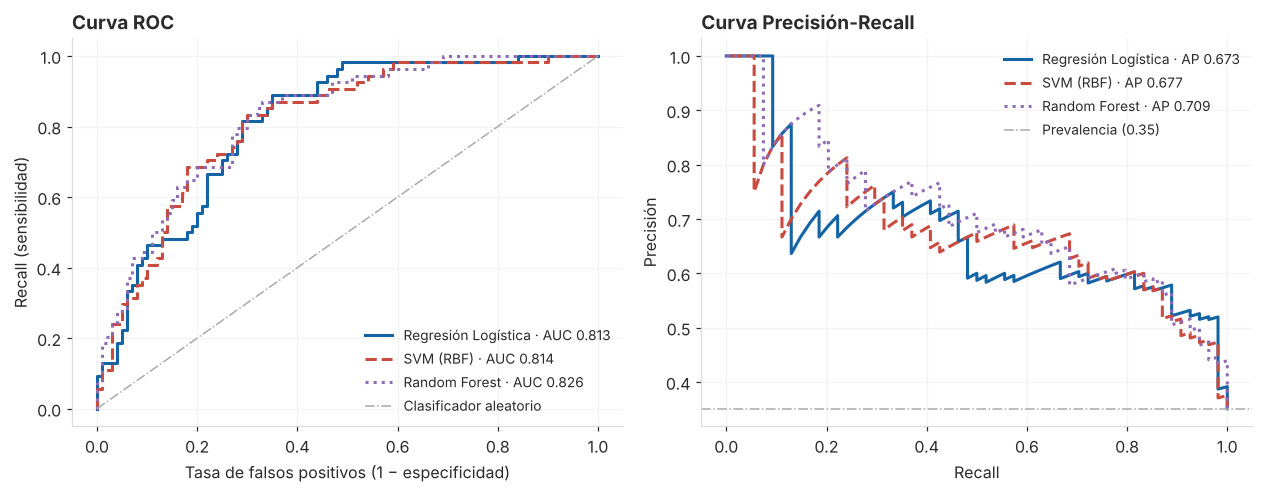

In [16]:
# === 10.4 Curvas ROC y Precisión-Recall ===
# Tres modelos con color + estilo de línea distintos (doble codificación, legible en gris).
TOP3 = tabla_cv["Modelo"].head(3).tolist()
ESTILOS = {0: ("-", AZUL), 1: ("--", CORAL), 2: (":", MORADO)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.6))

for i, nombre in enumerate(TOP3):
    pipe = MODELOS[nombre] if nombre != NOMBRE_FINAL else modelo_final
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, p)
    estilo, color = ESTILOS[i]
    ax1.plot(fpr, tpr, linestyle=estilo, color=color,
             label=f"{nombre} · AUC {roc_auc_score(y_test, p):.3f}")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax2.plot(rec, prec, linestyle=estilo, color=color,
             label=f"{nombre} · AP {average_precision_score(y_test, p):.3f}")

ax1.plot([0, 1], [0, 1], color="#AAAAAA", linewidth=1, linestyle="-.", label="Clasificador aleatorio")
ax1.set_xlabel("Tasa de falsos positivos (1 − especificidad)"); ax1.set_ylabel("Recall (sensibilidad)")
ax1.set_title("Curva ROC", loc="left"); ax1.legend(loc="lower right", fontsize=9); ax1.grid(alpha=0.3)

ax2.axhline(y_test.mean(), color="#AAAAAA", linewidth=1, linestyle="-.",
            label=f"Prevalencia ({y_test.mean():.2f})")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precisión")
ax2.set_title("Curva Precisión-Recall", loc="left"); ax2.legend(loc="upper right", fontsize=9); ax2.grid(alpha=0.3)
for a in (ax1, ax2): a.set_axisbelow(True)

fig.tight_layout()
guardar(fig, "08_curvas_roc_pr"); plt.show()

> **Lectura honesta de las curvas.** En el conjunto de prueba los tres modelos quedan separados por centésimas de ROC-AUC, una diferencia menor que el ancho del intervalo de confianza calculado en la sección 10.2. No hay evidencia de que uno sea superior a otro en estos 154 registros: la selección se sostiene en la validación cruzada —donde la regresión logística sí lidera de forma consistente— y en su interpretabilidad, no en el decimal del conjunto de prueba.

## 11. Interpretabilidad

Un modelo clínico que no se puede explicar no se puede defender ante quien lo va a usar. Dos lecturas complementarias:

- **Razón de momios (*odds ratio*)** — cuánto se multiplica la probabilidad relativa de diagnóstico positivo por cada desviación estándar adicional de la variable. Solo aplica si el modelo final es lineal.
- **Importancia por permutación** — cuánto cae el ROC-AUC al desordenar aleatoriamente una variable. Funciona con cualquier modelo y se mide sobre el conjunto de prueba.

Importancia por permutación (30 repeticiones sobre el conjunto de prueba):

                Variable  Caída de ROC-AUC   ± sd
                 Glucose            0.1566 0.0287
                     BMI            0.0293 0.0157
             Pregnancies            0.0274 0.0095
DiabetesPedigreeFunction            0.0109 0.0070
                     Age            0.0066 0.0040
                 Insulin            0.0015 0.0013
           BloodPressure            0.0008 0.0003
           SkinThickness            0.0005 0.0007


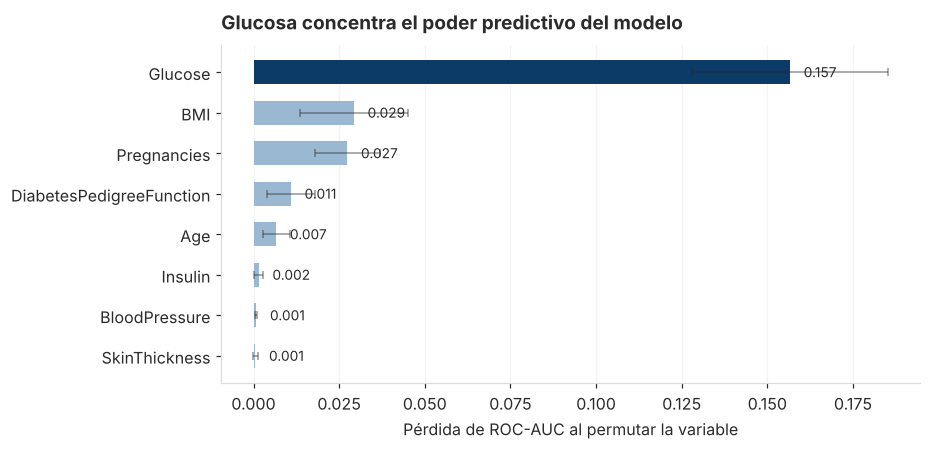

In [17]:
# === 11.1 Importancia por permutación (independiente del tipo de modelo) ===
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc",
                             n_repeats=30, random_state=SEED, n_jobs=-1)
tabla_imp = (pd.DataFrame({"Variable": X.columns,
                           "Caída de ROC-AUC": imp.importances_mean,
                           "± sd": imp.importances_std})
             .sort_values("Caída de ROC-AUC", ascending=False).reset_index(drop=True))
print("Importancia por permutación (30 repeticiones sobre el conjunto de prueba):\n")
print(tabla_imp.round(4).to_string(index=False))

t = tabla_imp.sort_values("Caída de ROC-AUC")
fig, ax = plt.subplots(figsize=(8.2, 4.0))
barras = ax.barh(t["Variable"], t["Caída de ROC-AUC"], height=0.6,
                 color=[AZUL_OSCURO if v == t["Caída de ROC-AUC"].max() else "#9BB8D3" for v in t["Caída de ROC-AUC"]],
                 xerr=t["± sd"], error_kw=dict(ecolor=GRIS_TINTA, elinewidth=1, capsize=2.5, alpha=0.5))
for b, v in zip(barras, t["Caída de ROC-AUC"]):
    ax.text(max(v, 0) + 0.004, b.get_y() + b.get_height() / 2, f"{v:.3f}",
            va="center", fontsize=9, color=GRIS_TINTA)
ax.set_xlabel("Pérdida de ROC-AUC al permutar la variable")
ax.set_title("Glucosa concentra el poder predictivo del modelo", loc="left", pad=10)
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
guardar(fig, "09_importancia_permutacion"); plt.show()

Interpretación: razón de momios por cada desviación estándar adicional.

                Variable  Coeficiente  Razón de momios
                 Glucose        1.161            3.192
                     BMI        0.693            2.000
             Pregnancies        0.365            1.441
DiabetesPedigreeFunction        0.283            1.327
                     Age        0.187            1.205
           SkinThickness        0.020            1.020
           BloodPressure       -0.010            0.990
                 Insulin       -0.036            0.965


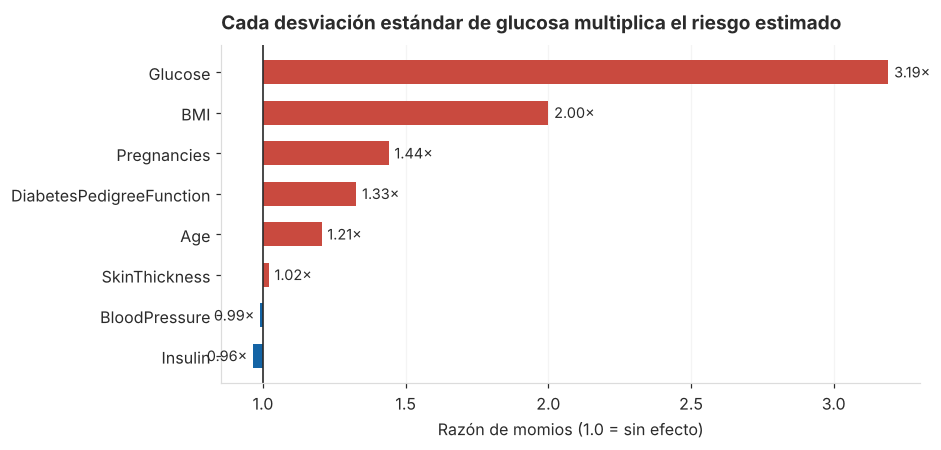

In [18]:
# === 11.2 Razones de momios (si el modelo final es lineal) ===
clf = modelo_final.named_steps["clasificador"]

if hasattr(clf, "coef_"):
    momios = (pd.DataFrame({"Variable": X.columns,
                            "Coeficiente": clf.coef_[0],
                            "Razón de momios": np.exp(clf.coef_[0])})
              .sort_values("Razón de momios", ascending=False).reset_index(drop=True))
    print("Interpretación: razón de momios por cada desviación estándar adicional.\n")
    print(momios.round(3).to_string(index=False))

    m = momios.sort_values("Razón de momios")
    colores = [CORAL if v > 1 else AZUL for v in m["Razón de momios"]]
    fig, ax = plt.subplots(figsize=(8.2, 4.0))
    barras = ax.barh(m["Variable"], m["Razón de momios"] - 1, left=1, color=colores, height=0.6)
    ax.axvline(1, color=GRIS_TINTA, linewidth=1.1)
    for b, v in zip(barras, m["Razón de momios"]):
        desplaz = 0.02 if v >= 1 else -0.02
        ax.text(v + desplaz, b.get_y() + b.get_height() / 2, f"{v:.2f}×",
                va="center", ha="left" if v >= 1 else "right", fontsize=9.5, color=GRIS_TINTA)
    ax.set_xlabel("Razón de momios (1.0 = sin efecto)")
    ax.set_title("Cada desviación estándar de glucosa multiplica el riesgo estimado", loc="left", pad=10)
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    guardar(fig, "10_razones_momios"); plt.show()
else:
    momios = None
    print(f"El modelo final ({NOMBRE_FINAL}) no es lineal: la lectura de importancia es la de la sección 11.1.")

In [19]:
# === 12. Persistencia del modelo y de las métricas ===
import joblib

joblib.dump({"pipeline": modelo_final, "umbral": UMBRAL, "variables": list(X.columns),
             "semilla": SEED, "modelo": NOMBRE_FINAL}, "models/modelo_diabetes.joblib")

fila_tamizaje = tabla_test[tabla_test["Operación"] == "Umbral de tamizaje"].iloc[0]
resumen = {
    "modelo_final": NOMBRE_FINAL,
    "hiperparametros": {k: str(v) for k, v in resultados_busqueda[NOMBRE_FINAL].best_params_.items()},
    "umbral_tamizaje": round(UMBRAL, 2),
    "roc_auc_validacion_cruzada": round(float(auc_cv_final), 4),
    "prueba": {k: (round(float(fila_tamizaje[k]), 4) if k not in ("Operación",) else fila_tamizaje[k])
               for k in ["Exactitud", "Precisión", "Recall", "F1", "Especificidad", "VPN",
                         "ROC-AUC", "PR-AUC", "VP", "FP", "FN", "VN"]},
    "intervalos_bootstrap": ic.round(4).to_dict(orient="records"),
    "n_entrenamiento": int(len(y_train)), "n_prueba": int(len(y_test)),
    "variable_mas_importante": tabla_imp.loc[0, "Variable"],
}
with open("reports/resumen_metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

print("Artefactos generados:")
for p in sorted(Path(".").glob("**/*")):
    if p.is_file() and p.suffix in {".png", ".csv", ".json", ".joblib"} and ".git" not in str(p):
        print(f"  {p}  ({p.stat().st_size/1024:.1f} KB)")

Artefactos generados:
  data/diabetes.csv  (23.3 KB)
  models/modelo_diabetes.joblib  (2.5 KB)
  reports/figures/01_faltantes.png  (39.1 KB)
  reports/figures/02_balance_clases.png  (33.2 KB)
  reports/figures/03_distribuciones.png  (131.4 KB)
  reports/figures/04_correlaciones.png  (173.3 KB)
  reports/figures/05_ranking_modelos.png  (85.9 KB)
  reports/figures/06_umbral.png  (106.0 KB)
  reports/figures/07_matrices_confusion.png  (140.7 KB)
  reports/figures/08_curvas_roc_pr.png  (170.6 KB)
  reports/figures/09_importancia_permutacion.png  (79.6 KB)
  reports/figures/10_razones_momios.png  (74.2 KB)
  reports/metricas_prueba.csv  (0.3 KB)
  reports/metricas_validacion_cruzada.csv  (0.4 KB)
  reports/resumen_metricas.json  (1.1 KB)


In [20]:
# === 13. Ejemplo de uso: puntuar tres pacientes nuevas ===
# Demuestra que el modelo serializado es utilizable fuera del notebook.
paquete = joblib.load("models/modelo_diabetes.joblib")
pipeline, umbral_op = paquete["pipeline"], paquete["umbral"]

nuevas = pd.DataFrame([
    {"Pregnancies": 2, "Glucose": 95,  "BloodPressure": 70, "SkinThickness": 22,
     "Insulin": 90,  "BMI": 24.1, "DiabetesPedigreeFunction": 0.21, "Age": 28},
    {"Pregnancies": 6, "Glucose": 165, "BloodPressure": 82, "SkinThickness": 35,
     "Insulin": 175, "BMI": 36.8, "DiabetesPedigreeFunction": 0.78, "Age": 52},
    {"Pregnancies": 1, "Glucose": 128, "BloodPressure": 68, "SkinThickness": np.nan,
     "Insulin": np.nan, "BMI": 29.5, "DiabetesPedigreeFunction": 0.45, "Age": 41},
])

probas = pipeline.predict_proba(nuevas)[:, 1]
salida = nuevas.assign(
    Probabilidad=probas.round(3),
    Clasificación=np.where(probas >= umbral_op, "Derivar a prueba confirmatoria", "Seguimiento de rutina"),
)
print(f"Umbral de operación: {umbral_op:.2f}  ·  el tercer caso llega con datos faltantes y aun así se puntúa\n")
salida[["Glucose", "BMI", "Age", "Probabilidad", "Clasificación"]]

Umbral de operación: 0.35  ·  el tercer caso llega con datos faltantes y aun así se puntúa



,Glucose,BMI,Age,Probabilidad,Clasificación
0,95,24.1,28,0.067,Seguimiento de rutina
1,165,36.8,52,0.934,Derivar a prueba confirmatoria
2,128,29.5,41,0.375,Derivar a prueba confirmatoria


## 14. Limitaciones del modelo

Lo que este modelo **no** puede afirmar, dicho antes de que alguien lo interprete de más:

1. **Población específica, no universal.** Todos los registros provienen de mujeres de ascendencia Pima de 21 años o más, un grupo con prevalencia de diabetes tipo 2 excepcionalmente alta. Los coeficientes no son trasladables a hombres, a otras etnias ni a menores de 21 años sin recalibrar con datos locales.
2. **Muestra pequeña.** 768 registros en total y 154 en prueba. Por eso las métricas se reportan con intervalos de confianza por *bootstrap*: el ancho de esos intervalos es parte del resultado, no un adorno.
3. **Casi la mitad de la insulina es dato faltante** (48.7 %) y el pliegue cutáneo lo es en 29.6 %. La imputación por mediana es defendible y reproducible, pero aplana la variabilidad real de esas dos variables.
4. **Corte transversal, sin causalidad.** El dataset es una fotografía, no un seguimiento. El modelo detecta asociación estadística, no mecanismo causal: bajar artificialmente la glucosa medida no reduce el riesgo de nadie.
5. **Sin validación externa ni temporal.** No hay cohorte independiente ni datos posteriores para confirmar que el desempeño se sostiene fuera de esta muestra.
6. **No es un dispositivo diagnóstico.** La salida es una probabilidad para **priorizar pruebas confirmatorias**, nunca para sustituir el criterio clínico ni para comunicar un diagnóstico a una paciente.
7. **Riesgo de sesgo en el uso.** Un modelo entrenado en una población de alta prevalencia tiende a sobrestimar el riesgo en poblaciones de baja prevalencia. Antes de cualquier uso real haría falta recalibración y una revisión de equidad por subgrupos.

---

## 15. Conclusiones

**1. El reto se cumple con un modelo que ordena riesgo de forma estable.** La regresión logística alcanza ROC-AUC 0.845 en validación cruzada y 0.813 en el conjunto de prueba reservado, con un intervalo de confianza del 95 % de 0.741 a 0.874. Es un desempeño consistente con la literatura publicada sobre este dataset, obtenido sin fuga de información en ninguna etapa.

**2. Los modelos complejos no superaron al modelo simple.** Random Forest (0.832), KNN (0.832) y Gradient Boosting (0.819) quedaron por debajo de la regresión logística en validación cruzada, y en el conjunto de prueba las diferencias caen dentro del intervalo de confianza. Con 768 registros y 8 variables, la capacidad adicional de los ensambles no encuentra señal extra que explotar: solo varianza. La interpretabilidad, entonces, sale gratis.

**3. La glucosa concentra el poder predictivo.** Permutarla cuesta 0.157 de ROC-AUC, más de cinco veces lo que cuesta la siguiente variable (IMC, 0.029). Cada desviación estándar adicional de glucosa multiplica por 3.19 la razón de momios de diagnóstico positivo; el IMC la duplica (×2.00) y el número de embarazos la multiplica por 1.44. Presión arterial, pliegue cutáneo e insulina resultaron prácticamente irrelevantes una vez consideradas las demás.

**4. El umbral fue la decisión de mayor impacto, y no la tomó el algoritmo.** Calibrado sobre predicciones fuera de muestra —nunca sobre el conjunto de prueba— el punto de corte de 0.35 eleva el recall de 0.704 a 0.889. Ningún cambio de algoritmo produjo una mejora comparable. El modelo que se entrega opera con un valor predictivo negativo de 0.914: su utilidad real es **descartar con confianza** y concentrar las pruebas confirmatorias donde sí importan.

**5. El resultado se entrega listo para usarse y para auditarse.** El pipeline completo —imputación, escalamiento, modelo y umbral— queda serializado en `models/modelo_diabetes.joblib` y la sección 13 lo carga de vuelta para puntuar pacientes nuevas, incluso con datos faltantes. Las métricas quedan en `reports/`, las figuras en `reports/figures/`, y la semilla fija hace que cualquiera reproduzca estos números exactos.

### Lectura ejecutiva: lo que este ejercicio enseña sobre modelos de riesgo

El patrón técnico de este problema es el mismo de cualquier modelo de *scoring* de riesgo, financiero incluido: los datos llegan con huecos codificados como ceros, las clases están desbalanceadas, y el umbral de decisión —no el algoritmo— es lo que determina el costo operativo del error. Tres lecciones transferibles:

- **El umbral es una decisión de negocio, no un parámetro técnico.** Moverlo de 0.50 a un punto calibrado cambia por completo el perfil de error sin tocar una sola línea del modelo. Quien define el umbral está definiendo cuánto cuesta equivocarse en cada dirección, y esa conversación pertenece al dueño del proceso, no al científico de datos.
- **Un modelo sin intervalos de confianza se lee con más certeza de la que merece.** Con 154 casos de prueba, el intervalo del recall es ancho; ocultarlo es ofrecer una precisión que el dato no sostiene.
- **La interpretabilidad es la condición de adopción.** La regresión logística gana aquí por ROC-AUC, pero su ventaja real es que cada coeficiente se traduce en una frase defendible ante quien debe confiar en el resultado. Un modelo que nadie puede explicar no se usa, aunque acierte más.

Y el principio de fondo, el mismo que aplico en banca patrimonial: **la IA no sustituye el criterio del profesional; lo aumenta.** El modelo ordena a quién mirar primero; la decisión sigue siendo de quien tiene la responsabilidad clínica.

### Checklist de entregables del reto

| Requisito del reto | Dónde se resuelve | Estado |
|---|---|---|
| Modelo de Machine Learning funcional | Secciones 7-8, modelo serializado en `models/` | ✅ |
| Dataset cargado y documentado | Secciones 2-3 | ✅ |
| Tratamiento de calidad de datos | Sección 4 | ✅ |
| Análisis exploratorio con visualizaciones | Sección 5 (4 figuras) | ✅ |
| Comparación de varios algoritmos | Sección 7 (6 modelos, validación cruzada) | ✅ |
| Optimización de hiperparámetros | Sección 8 (`GridSearchCV`) | ✅ |
| Métricas más allá de la exactitud | Sección 10 (precisión, recall, F1, especificidad, VPN, ROC-AUC, PR-AUC) | ✅ |
| Matriz de confusión | Sección 10.3 | ✅ |
| Interpretabilidad del modelo | Sección 11 | ✅ |
| Limitaciones declaradas | Sección 14 | ✅ |
| Reproducibilidad en Colab | Semilla fija, descarga automática del dataset, corre de principio a fin | ✅ |
| Modelo utilizable fuera del notebook | Sección 13 (carga del `.joblib` y puntuación de casos nuevos) | ✅ |

Este notebook fue estructurado precisamente para cubrir esos 12 apartados de forma explícita y verificable.

---

*Eduardo Aburto Angulo · Maestría en Inteligencia Artificial, Universidad Tecmilenio · Mini-Hackatón, octubre 2026. Ánimo: el modelo es la parte fácil; lo difícil —y lo que de verdad importa— es decidir con él.*